## Configuration


In [53]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
sys.path.append("../src")
from genera_datos import generar_datos, resumen

USAR_SINTETICOS = True   

if USAR_SINTETICOS:
    from genera_datos import generar_datos
    participacions, carreiras = generar_datos()
else:
    participacions = pd.read_csv("../datos/clean/participacions.csv")
    carreiras = pd.read_csv("../datos/clean/carreiras.csv")

In [54]:
print(participacions.head())
print(carreiras.head())

  persona_id  id_carrera  orden sexo   categoria  tipo_participante  tiempo_s  \
0      I0001  carrera_01      1    M  Veterano A  inscrito_circuito    3317.0   
1      I0002  carrera_01      1    M  Veterano B  inscrito_circuito    3669.0   
2      I0003  carrera_01      1    M      Senior  inscrito_circuito    3876.0   
3      I0004  carrera_01      1    F  Veterano B  inscrito_circuito    3773.0   
4      I0005  carrera_01      1    M      Senior  inscrito_circuito    2616.0   

  tiempo_estado  puesto_general  puesto_sexo  puesto_categoria  
0        valido              75           66                17  
1        valido             139          108                15  
2        valido             171          128                56  
3        valido             157           36                 7  
4        valido               3            3                 2  
   id_carrera  orden      fecha  distancia_km
0  carrera_01      1 2026-01-18          10.3
1  carrera_02      2 2026-03-01

## Participación
1. Participantes por sexo en cada carreira e evolución ao longo do circuíto.


In [55]:
print(participacions["sexo"])

# unstack() hace un pivot , porque sino tendriamos dos indices que serian sexo e id_carrera 
# al hacerlo pasamos que el id_carrera sea columnas y el sexo el indice, y si no forzamos
participacion_agrupado = participacions.groupby(["id_carrera","sexo"])["persona_id"].nunique().unstack()
print(participacion_agrupado)

0       M
1       M
2       M
3       F
4       M
       ..
1599    M
1600    M
1601    M
1602    F
1603    M
Name: sexo, Length: 1604, dtype: str
sexo         F    M
id_carrera         
carrera_01  76  146
carrera_02  74  145
carrera_03  60  151
carrera_04  90  131
carrera_05  64  125
carrera_06  60  126
carrera_07  57  118
carrera_08  65  116


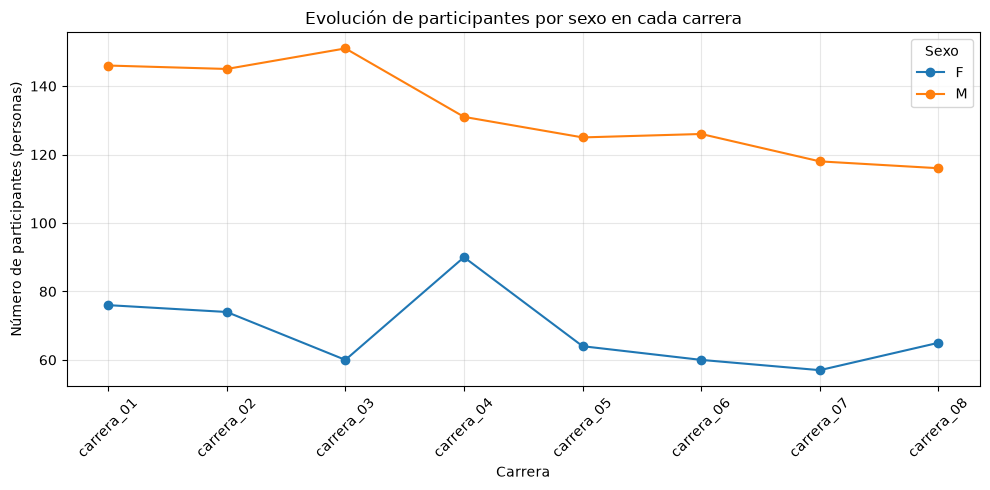

In [56]:
participacion_agrupado.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Evolución de participantes por sexo en cada carrera")
plt.xlabel("Carrera")
plt.ylabel("Número de participantes (personas)")
plt.legend(title="Sexo")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

2. Distribución por categorías de idade e diferenza entre sexos dentro de cada categoría.

In [57]:
print(participacions["categoria"])

participacions_idade = participacions.groupby(["categoria","sexo"])["persona_id"].nunique().unstack()

print(participacions_idade)

0       Veterano A
1       Veterano B
2           Senior
3       Veterano B
4           Senior
           ...    
1599        Senior
1600    Veterano B
1601        Senior
1602    Veterano A
1603        Senior
Name: categoria, Length: 1604, dtype: str
sexo         F    M
categoria          
Promesa     20   33
Senior      81  161
Veterano A  64  120
Veterano B  53   67
Veterano C  14   36


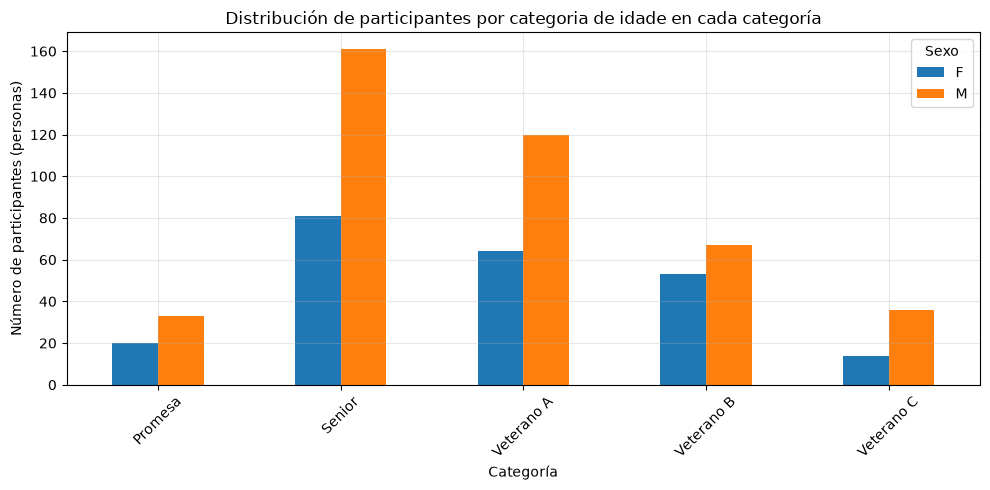

In [60]:
participacions_idade.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Distribución de participantes por categoria de idade en cada categoría")
plt.xlabel("Categoría")
plt.ylabel("Número de participantes (personas)")
plt.legend(title="Sexo")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()